# PNNL and EPRI grid-scale battery systems

This notebook lists the 12 released systems, loads the battery DC meter of one system, and plots its SOC. It makes no diagnosis.

## 1. Released units

This step lists what `systems('pnnl_epri')` reports for the release.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'fielddata').exists())
sys.path.insert(0, str(ROOT))
from fielddata import load, systems

released = systems('pnnl_epri')
display(released)

,unit,programme,chemistry,chemistry_source,cell_count,file,bytes
0,Avista,WACEF,vanadium flow,"Crawford 2026 DOE peer-review poster, alias ta...",not applicable,Avista.feather,792847866
1,ENW,WACEF,LFP,"Crawford 2026 DOE peer-review poster, alias ta...",not released,ENW.feather,6897434
2,EPRI_LFP1,EPRI,LFP,system name; poster (EPRI Li-Ion 3),not released,EPRI_LFP1.feather,349668578
3,EPRI_LFP2,EPRI,LFP,system name; poster (EPRI Li-Ion 5),not released,EPRI_LFP2.feather,112836682
4,EPRI_LFP3,EPRI,LFP,system name; poster (EPRI Li-Ion 4),not released,EPRI_LFP3.feather,366544250
5,EPRI_NMC1,EPRI,NMC,system name; poster (EPRI Li-Ion 2),not released,EPRI_NMC1.feather,43457362
6,EPRI_NMC2,EPRI,NMC,system name; poster (EPRI Li-Ion 1),not released,EPRI_NMC2.feather,331210418
7,EPRI_VRF1,EPRI,vanadium flow,system name; poster (EPRI Flow 1),not applicable,EPRI_VRF1.feather,56559410
8,OPALCO,WACEF,LFP,"Crawford 2026 DOE peer-review poster, alias ta...",not released,OPALCO.feather,18903466
9,PSE,WACEF,LFP,"Crawford 2026 DOE peer-review poster, alias ta...",not released,PSE.feather,343009050


Each row is one system, one .feather file. EPRI_NMC2 is the same system as the ppl release and is counted once, under ppl. The authors normalised power and current by ratings they do not release.

## 2. One unit as released

This step loads one unit with the default `clean=False`, so every value is as released.

In [2]:
frame = load('pnnl_epri', unit='ENW', meter='PDC', columns=['Voltage', 'Current', 'SOC', 'Power'])
print(frame.shape)
display(frame.head())

(85858, 6)


,HoursElapsed,Meter,Voltage,Current,SOC,Power
0,0.000000,PDC,3.213539,0.0,0.158,0.0
1,0.016667,PDC,3.213608,0.0,0.158,0.0
2,0.033333,PDC,3.213588,0.0,0.158,0.0
3,0.050000,PDC,3.213574,0.0,0.158,0.0
4,0.066667,PDC,3.213539,0.0,0.158,0.0


ENW's battery DC meter over 1,431 hours of elapsed time. Power and current are C-rates (1/h), voltage is per cell, and SOC is a fraction.

## 3. Signal ranges

This step summarises a few signals of the loaded unit.

In [3]:
display(frame[['Voltage', 'Current', 'SOC', 'Power']].describe().T)

,count,mean,std,min,25%,50%,75%,max
Voltage,70105.0,3.306786,0.079078,0.108520,3.250108,3.343725,3.349902,3.447657
Current,85858.0,-0.001290,0.065340,-0.178717,0.000000,0.000000,0.000000,0.195761
SOC,85858.0,0.587152,0.315765,0.047617,0.227000,0.710942,0.890000,0.955000
Power,70105.0,-0.002236,0.071512,-0.171407,0.000000,0.000000,0.000000,0.178752


These ranges are raw values as released, before any cleaning. The schema file next to the loader lists units and any sentinel codes.

## 4. A first look

This step plots one signal to show the shape of the data.

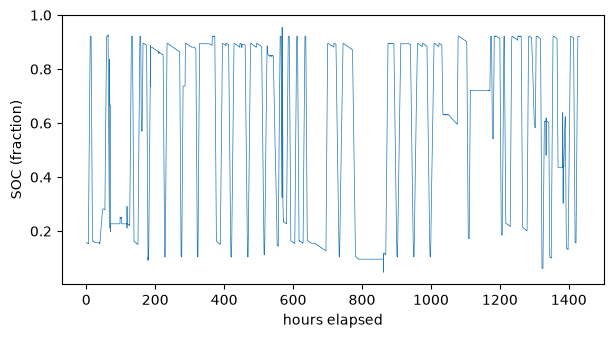

In [4]:
ax = frame.plot(x='HoursElapsed', y='SOC', figsize=(7, 3.5), lw=0.5, legend=False)
ax.set_xlabel('hours elapsed')
ax.set_ylabel('SOC (fraction)')
plt.show()

Over ENW's 1,431 hours SOC moves between 0.05 and 0.96, with a median of 0.71.